# 16 — EKF / UKF baselines against the production SBI posterior (System I, N3)

**Why.** The paper needs the industrial comparator: a joint state–parameter EKF / UKF with the same model, the same sensors and, where
the production posterior is given them, the same inlet information. The old notebook 16 used the malformed PI law (no Kp on the integral
term; fixed 2026-11-08), a 60-min window, the old sensor noise and the old summary-set SBI posterior, so none of its numbers carry over.
`scripts/ws_filters.py` (tests: `tests/test_ws_filters.py`) rebuilds the filters on the physics constants and the standard PI law.

**Variants (fixed before running; runbook §2f row c).**
* **aug** — 8-state: [C, T, Tc, I, α, β] plus two constant offset states (dTi, dTci, prior sd 0.1 K); the *measured* inlet temperatures
  are known inputs and the plant sees measured − offset. This is the filter counterpart of the production posterior's inlet model.
* **known** — 6-state, measured inlet temperatures as known inputs, no offset states.
* **naive** — 6-state, nominal inlet (297 K, 297 K) assumed: valid on D0 (nominal-inlet data), a sensitivity test on D1.

**Data.** D1 (`observations_measured_inlet.npz`, Sc1–Sc5 and Sc7 × 50, measured inlet) for aug / known / naive; D0
(`observations.npz`, same scenarios, nominal inlet) for naive. One configuration of each filter for every scenario (no tuning per
scenario); N3 sensor sd in R. The SBI production row is read from notebook 11's table (same D1 windows).

**Three numbers per method and scenario**, as in notebook 11: class accuracy (quadrant mass of independent Gaussians N(estimate, sd),
threshold 0.90, 2,000 draws), β 90% coverage (|estimate − truth| < 1.645 sd), β sd (mean reported sd); plus bias, RMSE and the
empirical sd of the estimates, and ms per window. **Checks:** (0) the filter tests pass; (1) all estimates finite with positive
variances (stop if > 5% of windows fail in a variant); (2) naive filter on D0 Sc1: |α bias|, |β bias| < 0.30; (3) mean aug dTci estimate on
D1 within ±0.3 K. No decision rule. Tracking on the new 30-day stream is added after notebook 10 is rebuilt.

**Tuning (c3; user rule, fixed before running; runbook §2f row c3).** The filters above use one hand-set Q, R, P0. To make the comparison fair they are also tuned,
once, on a **separate tuning set**: 50 windows per scenario for Sc1–Sc5 (250 windows), new seed base 4 100 000, generated like D1 (measured inlet, P2, N3). A 5 × 5 grid of scale
factors on the process-noise Q and on the measurement-noise R, each in {0.25, 0.5, 1, 2, 4}; objective = the mean predictive log-likelihood of the measurements (the summed Gaussian innovation
log-density of each window, averaged over windows), separately for the augmented EKF and UKF, one setting each for all scenarios. The tuned augmented filters are then re-evaluated on the D1
test windows (not used in tuning) and set next to the untuned numbers (coverage, RMSE, tail count: |β error| > 0.15). A boundary optimum is flagged, not extended. The tail windows of the untuned run are examined
(initialisation, divergence, observability) and reported.


In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, ws_filters, ws_metrics, ws_phase3
for _m in (ws_filters, ws_metrics, ws_phase3):
    importlib.reload(_m)
F, wm, P3 = ws_filters, ws_metrics, ws_phase3
T0 = time.time(); R = ROOT / "results"
SCN = {1: "Sc1", 2: "Sc2", 3: "Sc3", 4: "Sc4", 5: "Sc5", 7: "Sc7"}
# check 0: the filter tests
r = subprocess.run([sys.executable, "-m", "pytest", "tests/test_ws_filters.py", "-q"], cwd=ROOT, capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])
assert r.returncode == 0, r.stdout[-2000:]
d1, d0 = P3.load_d1(), P3.load_d0()
keep0 = np.isin(d0["scenario_id"], list(SCN))
print("D1:", d1["x"].shape, "| D0 (Sc1-5, Sc7):", int(keep0.sum()), "windows")


24 passed, 1 warning in 3.32s
D1: (300, 120, 4) | D0 (Sc1-5, Sc7): 300 windows


## 1. Run the filters (serial; UKF is the slow one)

In [2]:
def run(d, ids, method, mode):
    rows = []
    for i in ids:
        if mode == "naive":
            ti, tci, aug = F.TI0, F.TCI0, False
        else:
            ti, tci = (float(v) for v in d["inlet_measured"][i]); aug = mode == "aug"
        try:
            o = F.estimate_window(d["x"][i], method, ti, tci, F.CI0, augment=aug)
        except Exception as e:                      # a filter failure is counted, not hidden
            o = dict(alpha=np.nan, beta=np.nan, sd_alpha=np.nan, sd_beta=np.nan, wall_s=np.nan, dTi=np.nan, dTci=np.nan, err=str(e)[:80])
        rows.append(dict(win=int(i), sc=int(d["scenario_id"][i]), a_true=float(d["theta"][i, 2]), b_true=float(d["theta"][i, 3]),
                         a=o["alpha"], b=o["beta"], sd_a=o["sd_alpha"], sd_b=o["sd_beta"], ms=1000 * o["wall_s"],
                         dTci=o.get("dTci", np.nan), sat=float((d["x"][i][:, 3] >= 395).mean())))
    out = pd.DataFrame(rows); out["method"] = method.upper(); out["variant"] = mode
    return out

res = {}
ids1 = np.arange(len(d1["x"])); ids0 = np.where(keep0)[0]
for dname, d, ids, modes in (("D1", d1, ids1, ("aug", "known", "naive")), ("D0", d0, ids0, ("naive",))):
    for mode in modes:
        for method in ("ekf", "ukf"):
            t = time.time(); res[(dname, mode, method)] = run(d, ids, method, mode)
            print(f"{dname} {mode:5s} {method.upper()}: {time.time() - t:6.1f}s", flush=True)
allres = pd.concat([v.assign(data=k[0]) for k, v in res.items()], ignore_index=True)
print("total", len(allres), "estimates | wall %.1f min" % ((time.time() - T0) / 60))


D1 aug   EKF:   10.3s


D1 aug   UKF:  153.8s


D1 known EKF:    9.6s


D1 known UKF:  110.3s


D1 naive EKF:    9.3s


D1 naive UKF:  107.7s


D0 naive EKF:    9.3s


D0 naive UKF:  108.1s


total 2400 estimates | wall 8.7 min


## 2. Checks 1–3

In [3]:
bad = allres.groupby(["data", "variant", "method"]).apply(lambda g: float((~np.isfinite(g[["a", "b", "sd_a", "sd_b"]]).all(axis=1) | (g.sd_a <= 0) | (g.sd_b <= 0)).mean()))
print("fraction of failed windows per variant:\n", bad.round(4).to_string())
assert (bad <= 0.05).all(), "check 1 failed"
s1 = allres[(allres.data == "D0") & (allres.sc == 1) & (allres.variant == "naive")].groupby("method")[["a", "b", "a_true", "b_true"]].mean()
print("\nD0 Sc1 naive filter, mean estimate:\n", s1.round(3).to_string())
for m, row in s1.iterrows():
    assert abs(row.a - row.a_true) < 0.30 and abs(row.b - row.b_true) < 0.30, f"check 2 failed ({m})"
dt = allres[(allres.data == "D1") & (allres.variant == "aug")].groupby("method").dTci.mean()
print("\nmean aug dTci estimate on D1 (K):", dt.round(3).to_dict())
assert (dt.abs() < 0.3).all(), "check 3 failed"
print("checks 0-3 passed")


fraction of failed windows per variant:
 data  variant  method
D0    naive    EKF       0.0
               UKF       0.0
D1    aug      EKF       0.0
               UKF       0.0
      known    EKF       0.0
               UKF       0.0
      naive    EKF       0.0
               UKF       0.0

D0 Sc1 naive filter, mean estimate:
             a      b  a_true  b_true
method                              
EKF     0.978  1.013     1.0     1.0
UKF     0.973  0.980     1.0     1.0

mean aug dTci estimate on D1 (K): {'EKF': 0.015, 'UKF': -0.07}
checks 0-3 passed


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_59104/3752016885.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bad = allres.groupby(["data", "variant", "method"]).apply(lambda g: float((~np.isfinite(g[["a", "b", "sd_a", "sd_b"]]).all(axis=1) | (g.sd_a <= 0) | (g.sd_b <= 0)).mean()))


## 3. Three numbers per method and scenario (D1, headline) with the SBI production row

In [4]:
CLS = list(wm.CLASSES)
rng = np.random.default_rng(0)

def classify(g):
    z = rng.standard_normal((len(g), 2000, 2))
    smp = np.stack([g.a.values[:, None] + g.sd_a.values[:, None] * z[:, :, 0], g.b.values[:, None] + g.sd_b.values[:, None] * z[:, :, 1]], axis=2)
    return wm.class_of_samples(smp)

def summarise(df):
    out = []
    for (meth, var, sc), g in df.groupby(["method", "variant", "sc"]):
        g = g[np.isfinite(g[["a", "b", "sd_a", "sd_b"]]).all(axis=1)]
        yt = wm.class_of_theta(np.column_stack([g.a_true, g.b_true])); yp = classify(g)
        eb, ea = g.b - g.b_true, g.a - g.a_true
        out.append(dict(method=meth, variant=var, scenario=SCN[sc], n=len(g), class_acc=float((yt == yp).mean()),
                        cov90_b=float((eb.abs() < 1.645 * g.sd_b).mean()), sd_b=float(g.sd_b.mean()), bias_b=float(eb.mean()),
                        rmse_b=float(np.sqrt((eb ** 2).mean())), emp_sd_b=float(g.b.std()),
                        cov90_a=float((ea.abs() < 1.645 * g.sd_a).mean()), sd_a=float(g.sd_a.mean()), bias_a=float(ea.mean()),
                        rmse_a=float(np.sqrt((ea ** 2).mean())), ms_per_window=float(g.ms.mean())))
    return pd.DataFrame(out)

t1 = summarise(allres[(allres.data == "D1") & (allres.variant.isin(["aug", "known"]))])
sbi = pd.read_csv(R / "11_N3_D1_three_numbers.csv")
sbi_rows = pd.DataFrame(dict(method="SBI (production)", variant="measured inlet", scenario=sbi.scenario, n=sbi.n, class_acc=sbi.class_acc,
                             cov90_b=sbi.cov90_b, sd_b=sbi.sd_b, bias_b=sbi.bias_b, sd_a=sbi.sd_a))
cmp = pd.concat([t1, sbi_rows], ignore_index=True)
cmp["scenario"] = pd.Categorical(cmp.scenario, list(SCN.values()))
cols = ["method", "variant", "scenario", "n", "class_acc", "cov90_b", "sd_b", "bias_b", "rmse_b", "emp_sd_b", "sd_a", "bias_a", "rmse_a", "ms_per_window"]
cmp = cmp.sort_values(["scenario", "method", "variant"])[cols]
display(cmp.round(3).reset_index(drop=True))
cmp.to_csv(R / "16_N3_D1_comparison.csv", index=False)


,method,variant,scenario,n,class_acc,cov90_b,sd_b,bias_b,rmse_b,emp_sd_b,sd_a,bias_a,rmse_a,ms_per_window
0,EKF,aug,Sc1,50,0.90,0.64,0.028,-0.029,0.119,0.117,0.048,-0.015,0.057,34.360
1,EKF,known,Sc1,50,0.90,0.30,0.018,-0.019,0.119,0.119,0.048,-0.017,0.059,32.618
2,SBI (production),measured inlet,Sc1,50,0.98,0.96,0.046,0.000,NaN,NaN,0.055,NaN,NaN,NaN
3,UKF,aug,Sc1,50,0.90,0.86,0.033,-0.023,0.042,0.035,0.047,-0.013,0.063,504.919
4,UKF,known,Sc1,50,0.84,0.48,0.021,-0.051,0.175,0.169,0.047,-0.012,0.066,386.080
5,EKF,aug,Sc2,50,0.86,0.78,0.031,-0.003,0.088,0.089,0.049,-0.011,0.059,33.786
6,EKF,known,Sc2,50,0.76,0.36,0.020,0.001,0.106,0.107,0.049,-0.011,0.061,32.059
7,SBI (production),measured inlet,Sc2,50,0.82,0.94,0.046,0.007,NaN,NaN,0.056,NaN,NaN,NaN
8,UKF,aug,Sc2,50,0.90,0.76,0.033,-0.010,0.044,0.043,0.048,-0.005,0.060,531.535
9,UKF,known,Sc2,50,0.76,0.40,0.021,0.004,0.064,0.065,0.049,-0.000,0.062,366.982


## 4. Naive filters: valid on D0, sensitivity on D1 (nominal inlet assumed)

In [5]:
tn = pd.concat([summarise(allres[(allres.data == "D0")]).assign(data="D0 (nominal inlet, naive valid)"),
                summarise(allres[(allres.data == "D1") & (allres.variant == "naive")]).assign(data="D1 (inlet varies, naive assumes nominal)")], ignore_index=True)
tn = tn[["data", "method", "scenario", "n", "class_acc", "cov90_b", "sd_b", "bias_b", "rmse_b", "emp_sd_b", "bias_a", "rmse_a", "ms_per_window"]]
display(tn.round(3).sort_values(["data", "scenario", "method"]).reset_index(drop=True))
tn.to_csv(R / "16_N3_naive_D0_vs_D1.csv", index=False)


,data,method,scenario,n,class_acc,cov90_b,sd_b,bias_b,rmse_b,emp_sd_b,bias_a,rmse_a,ms_per_window
0,"D0 (nominal inlet, naive valid)",EKF,Sc1,50,0.94,0.60,0.010,0.013,0.019,0.015,-0.022,0.056,30.824
1,"D0 (nominal inlet, naive valid)",UKF,Sc1,50,0.92,0.50,0.013,-0.020,0.027,0.018,-0.027,0.058,358.843
2,"D0 (nominal inlet, naive valid)",EKF,Sc2,50,0.98,0.84,0.014,-0.001,0.015,0.015,-0.007,0.051,30.844
3,"D0 (nominal inlet, naive valid)",UKF,Sc2,50,0.96,0.82,0.015,-0.009,0.018,0.016,-0.009,0.051,358.460
4,"D0 (nominal inlet, naive valid)",EKF,Sc3,50,1.00,0.62,0.010,0.010,0.020,0.017,-0.004,0.030,30.708
5,"D0 (nominal inlet, naive valid)",UKF,Sc3,50,1.00,0.52,0.014,-0.021,0.028,0.019,-0.008,0.031,357.503
6,"D0 (nominal inlet, naive valid)",EKF,Sc4,50,0.94,0.84,0.013,0.007,0.018,0.017,-0.006,0.037,30.891
7,"D0 (nominal inlet, naive valid)",UKF,Sc4,50,0.94,0.80,0.014,-0.007,0.020,0.019,-0.007,0.040,358.319
8,"D0 (nominal inlet, naive valid)",EKF,Sc5,50,0.96,0.90,0.026,0.004,0.026,0.026,-0.019,0.051,31.385
9,"D0 (nominal inlet, naive valid)",UKF,Sc5,50,0.98,0.90,0.025,0.002,0.026,0.026,-0.004,0.048,358.064


## 5. Saturation split (D1; saturated = more than 50% of the window's samples at Qc ≥ 395 L/min)

In [6]:
g = allres[(allres.data == "D1") & (allres.variant.isin(["aug", "known"]))].copy()
g["group"] = np.where(g.sat > 0.5, "saturated", "unsaturated")
rows = []
for (meth, var, grp), gg in g.groupby(["method", "variant", "group"]):
    gg = gg[gg.sc != 7]
    eb = gg.b - gg.b_true
    rows.append(dict(method=meth, variant=var, group=grp, n=len(gg), bias_b=float(eb.mean()), rmse_b=float(np.sqrt((eb ** 2).mean())),
                     cov90_b=float((eb.abs() < 1.645 * gg.sd_b).mean()), sd_b=float(gg.sd_b.mean())))
sat = pd.DataFrame(rows); display(sat.round(3)); sat.to_csv(R / "16_N3_saturation_split.csv", index=False)
print("(Sc7, the +2 K sensor drift, is excluded from the saturation split.)")


,method,variant,group,n,bias_b,rmse_b,cov90_b,sd_b
0,EKF,aug,saturated,93,-0.003,0.045,0.828,0.039
1,EKF,aug,unsaturated,157,-0.011,0.112,0.592,0.022
2,EKF,known,saturated,93,0.002,0.097,0.355,0.027
3,EKF,known,unsaturated,157,-0.015,0.100,0.357,0.013
4,UKF,aug,saturated,93,-0.005,0.045,0.849,0.038
5,UKF,aug,unsaturated,157,-0.033,0.088,0.675,0.028
6,UKF,known,saturated,93,-0.004,0.088,0.344,0.026
7,UKF,known,unsaturated,157,-0.046,0.140,0.408,0.017


(Sc7, the +2 K sensor drift, is excluded from the saturation split.)


## 6. Figure: β̂ by scenario and filter variant

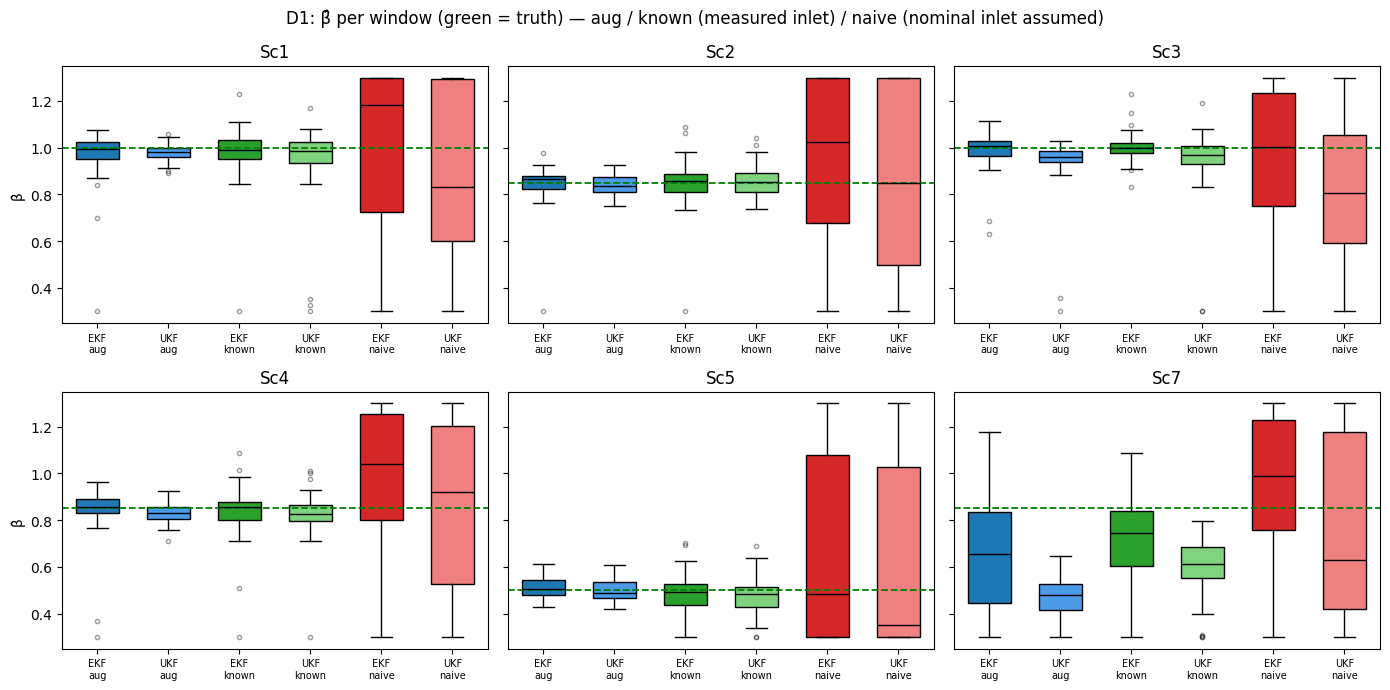

notebook wall time 8.7 min


In [7]:
FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True)
combo = [("D1", "aug", "ekf"), ("D1", "aug", "ukf"), ("D1", "known", "ekf"), ("D1", "known", "ukf"), ("D1", "naive", "ekf"), ("D1", "naive", "ukf")]
cols_ = ["#1f77b4", "#4c9be8", "#2ca02c", "#7fd37f", "#d62728", "#f08080"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, (sc, nm) in zip(axes.flat, SCN.items()):
    for k, (key, c) in enumerate(zip(combo, cols_)):
        v = res[key]; v = v[v.sc == sc]
        bp = ax.boxplot(v.b.dropna().values, positions=[k], widths=0.6, patch_artist=True, flierprops=dict(ms=3, alpha=0.4))
        bp["boxes"][0].set_facecolor(c); bp["medians"][0].set_color("black")
    ax.axhline(float(res[combo[0]][res[combo[0]].sc == sc].b_true.iloc[0]), color="green", ls="--", lw=1.3)
    ax.set_xticks(range(6)); ax.set_xticklabels([f"{k[2].upper()}\n{k[1]}" for k in combo], fontsize=7); ax.set_title(nm)
axes[0, 0].set_ylabel("β̂"); axes[1, 0].set_ylabel("β̂")
fig.suptitle("D1: β̂ per window (green = truth) — aug / known (measured inlet) / naive (nominal inlet assumed)")
fig.tight_layout(); fig.savefig(FIGS / "16_N3_beta_by_variant.png", dpi=150); plt.show()
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")


## 7. Timing

Reported as ms per window in the tables above (single process, NumPy; the production posterior is amortised: the cost is the 3-D
network forward pass and 2,000 draws per window, measured in notebook 12).

## 8. Per-window estimates

Stored in `results/16_N3_window_estimates.csv` for the later notebooks.

In [8]:
allres.to_csv(R / "16_N3_window_estimates.csv", index=False)
print("saved", (R / "16_N3_window_estimates.csv").relative_to(ROOT), len(allres), "rows")


saved results/16_N3_window_estimates.csv 2400 rows


## 8b. c3 — fair tuning of the augmented filters on a separate tuning set

In [9]:
import concurrent.futures as cf
os.environ["OMP_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
dT = P3.generate_d1(seed_base=4_100_000, n_rep=50)
mT = dT["scenario_id"] != 7
assert mT.sum() == 250 and not set(dT["seeds"].tolist()) & set(d1["seeds"].tolist())
GRID = [0.25, 0.5, 1.0, 2.0, 4.0]
def grid_ll(method):
    tasks = [(dT["x"][i], method, float(dT["inlet_measured"][i, 0]), float(dT["inlet_measured"][i, 1]), True, qs, rs)
             for qs in GRID for rs in GRID for i in np.where(mT)[0]]
    with cf.ProcessPoolExecutor(max_workers=9) as ex:
        out = np.array(list(ex.map(F.loglik_window, tasks, chunksize=25)))
    return out.reshape(len(GRID), len(GRID), -1)
tun = {}
for method in ("ekf", "ukf"):
    t = time.time(); L = grid_ll(method)
    fin = np.isfinite(L)
    mean_ll = np.where(fin.all(axis=2), L.mean(axis=2), np.nan)       # a setting with any failed window is not eligible
    tun[method] = mean_ll
    qi, ri = np.unravel_index(np.nanargmax(mean_ll), mean_ll.shape)
    print(f"{method.upper()}: {time.time() - t:.0f}s | failed windows in the grid: {int((~fin).sum())} | best q_scale {GRID[qi]}, r_scale {GRID[ri]}, mean log-lik per window {mean_ll[qi, ri]:.1f}"
          + (" | BOUNDARY OPTIMUM" if qi in (0, len(GRID) - 1) or ri in (0, len(GRID) - 1) else " | interior"))
    display(pd.DataFrame(mean_ll, index=[f"q x{g}" for g in GRID], columns=[f"r x{g}" for g in GRID]).round(1))
    pd.DataFrame(mean_ll, index=GRID, columns=GRID).to_csv(R / f"16_N3_tuning_grid_{method}.csv")
BEST = {m: (GRID[np.unravel_index(np.nanargmax(v), v.shape)[0]], GRID[np.unravel_index(np.nanargmax(v), v.shape)[1]]) for m, v in tun.items()}
print("tuned (q_scale, r_scale):", BEST)


EKF: 34s | failed windows in the grid: 0 | best q_scale 2.0, r_scale 2.0, mean log-lik per window -116.5 | interior


,r x0.25,r x0.5,r x1.0,r x2.0,r x4.0
q x0.25,-1858.9,-709.7,-325.6,-164.5,-161.1
q x0.5,-1231.6,-521.4,-214.5,-130.9,-139.0
q x1.0,-766.7,-340.5,-208.5,-133.2,-144.4
q x2.0,-617.2,-269.8,-132.3,-116.5,-160.2
q x4.0,-524.5,-249.9,-118.1,-121.8,-175.0


UKF: 414s | failed windows in the grid: 0 | best q_scale 0.25, r_scale 2.0, mean log-lik per window -79.9 | BOUNDARY OPTIMUM


,r x0.25,r x0.5,r x1.0,r x2.0,r x4.0
q x0.25,-1650.7,-1073.0,-385.9,-79.9,-136.8
q x0.5,-1392.1,-854.2,-459.9,-96.4,-122.7
q x1.0,-1265.1,-561.7,-419.2,-127.0,-120.3
q x2.0,-823.6,-404.8,-216.2,-188.2,-128.1
q x4.0,-512.5,-276.0,-132.1,-106.4,-156.3


tuned (q_scale, r_scale): {'ekf': (2.0, 2.0), 'ukf': (0.25, 2.0)}


### Tuned versus untuned on the D1 test windows (augmented filters)

In [10]:
def run_tuned(method, qs, rs):
    rows = []
    for i in range(len(d1["x"])):
        ti, tci = (float(v) for v in d1["inlet_measured"][i])
        o = F.estimate_window(d1["x"][i], method, ti, tci, F.CI0, augment=True, q_scale=qs, r_scale=rs)
        rows.append(dict(win=i, sc=int(d1["scenario_id"][i]), a_true=float(d1["theta"][i, 2]), b_true=float(d1["theta"][i, 3]), a=o["alpha"], b=o["beta"],
                         sd_a=o["sd_alpha"], sd_b=o["sd_beta"], ms=1000 * o["wall_s"], dTci=o["dTci"], sat=float((d1["x"][i][:, 3] >= 395).mean())))
    out = pd.DataFrame(rows); out["method"] = method.upper(); out["variant"] = "aug_tuned"; return out
tuned = pd.concat([run_tuned(m, *BEST[m]) for m in ("ekf", "ukf")], ignore_index=True)
assert np.isfinite(tuned[["a", "b", "sd_a", "sd_b"]]).all().all()
base = allres[(allres.data == "D1") & (allres.variant == "aug")].copy()
def tail_stats(df):
    out = []
    for (m, sc), g in df.groupby(["method", "sc"]):
        eb = g.b - g.b_true
        out.append(dict(method=m, scenario=SCN[sc], n=len(g), cov90_b=float((eb.abs() < 1.645 * g.sd_b).mean()), rmse_b=float(np.sqrt((eb ** 2).mean())),
                        bias_b=float(eb.mean()), sd_b=float(g.sd_b.mean()), n_tail=int((eb.abs() > 0.15).sum())))
    return pd.DataFrame(out)
cmp3 = tail_stats(base).merge(tail_stats(tuned), on=["method", "scenario", "n"], suffixes=("_untuned", "_tuned"))
cmp3 = cmp3.sort_values(["method", "scenario"]); display(cmp3.round(3))
pool = []
for lab, df in (("untuned", base), ("tuned", tuned)):
    for m, g in df[df.sc != 7].groupby("method"):
        eb = g.b - g.b_true; ea = g.a - g.a_true
        pool.append(dict(variant=lab, method=m, n=len(g), cov90_b=float((eb.abs() < 1.645 * g.sd_b).mean()), rmse_b=float(np.sqrt((eb ** 2).mean())), n_tail_b=int((eb.abs() > 0.15).sum()),
                         cov90_a=float((ea.abs() < 1.645 * g.sd_a).mean()), rmse_a=float(np.sqrt((ea ** 2).mean())), median_abs_err_b=float(eb.abs().median()), mean_sd_b=float(g.sd_b.mean())))
pooled = pd.DataFrame(pool); display(pooled.round(3))
cmp3.to_csv(R / "16_N3_tuned_vs_untuned.csv", index=False); pooled.to_csv(R / "16_N3_tuned_vs_untuned_pooled_Sc1_5.csv", index=False)
tuned.to_csv(R / "16_N3_window_estimates_tuned.csv", index=False)


,method,scenario,n,cov90_b_untuned,rmse_b_untuned,bias_b_untuned,sd_b_untuned,n_tail_untuned,cov90_b_tuned,rmse_b_tuned,bias_b_tuned,sd_b_tuned,n_tail_tuned
0,EKF,Sc1,50,0.64,0.119,-0.029,0.028,3,0.66,0.115,-0.029,0.035,2
1,EKF,Sc2,50,0.78,0.088,-0.003,0.031,1,0.88,0.088,-0.007,0.039,1
2,EKF,Sc3,50,0.58,0.082,-0.011,0.024,2,0.70,0.062,-0.007,0.030,1
3,EKF,Sc4,50,0.64,0.113,-0.009,0.027,2,0.72,0.106,-0.011,0.034,2
4,EKF,Sc5,50,0.76,0.045,0.011,0.033,0,0.86,0.045,0.013,0.043,0
5,EKF,Sc7,50,0.22,0.315,-0.199,0.026,30,0.28,0.304,-0.189,0.033,29
6,UKF,Sc1,50,0.86,0.042,-0.023,0.033,0,0.70,0.041,-0.016,0.026,0
7,UKF,Sc2,50,0.76,0.044,-0.010,0.033,0,0.62,0.046,-0.001,0.026,0
8,UKF,Sc3,50,0.62,0.143,-0.063,0.029,2,0.66,0.047,-0.023,0.025,1
9,UKF,Sc4,50,0.70,0.044,-0.019,0.031,0,0.74,0.039,-0.008,0.025,0


,variant,method,n,cov90_b,rmse_b,n_tail_b,cov90_a,rmse_a,median_abs_err_b,mean_sd_b
0,untuned,EKF,250,0.680,0.093,8,0.836,0.050,0.030,0.028
1,untuned,UKF,250,0.740,0.075,2,0.824,0.050,0.033,0.032
2,tuned,EKF,250,0.764,0.087,6,0.936,0.048,0.032,0.036
3,tuned,UKF,250,0.672,0.044,1,0.900,0.051,0.029,0.025


### The untuned tail windows: initialisation, divergence or observability?

In [11]:
tails = base[(base.sc != 7) & ((base.b - base.b_true).abs() > 0.15)].copy()
rows = []
for _, w in tails.iterrows():
    i = int(w.win); ti, tci = (float(v) for v in d1["inlet_measured"][i]); aug = True
    plant = F.Plant(ti, tci, F.CI0, aug); Q, R_, P0 = F.default_noise(aug)
    x0 = F.make_x0(d1["x"][i][0], aug)
    run_ = F.run_ekf if w.method == "EKF" else F.run_ukf
    xh, Ph = run_(plant, np.asarray(d1["x"][i], float), x0, P0, Q, R_)
    I0_raw = F.TAUI * ((d1["x"][i][0, 3] - F.QC0) / F.KP - (d1["x"][i][0, 1] - F.TSP))
    eps_ti, eps_tci = (d1["inlet_measured"][i] - d1["inlet_true"][i][1:3])
    rows.append(dict(method=w.method, window=i, scenario=SCN[int(w.sc)], beta_true=w.b_true, beta_hat=w.b, sd_b=w.sd_b,
                     beta_at_5min=xh[9, 5], beta_at_15min=xh[29, 5], beta_at_30min=xh[59, 5], sd_b_at_5min=float(np.sqrt(Ph[9, 5, 5])), sd_b_end=float(np.sqrt(Ph[-1, 5, 5])),
                     at_bound=bool(w.b < 0.31 or w.b > 1.29), I0_raw=float(I0_raw), I0_clipped=bool(abs(I0_raw) > 100),
                     dTci_hat=w.dTci, err_Tci_meas_minus_true=float(eps_tci), err_Ti_meas_minus_true=float(eps_ti), true_Ti=float(d1["inlet_true"][i][1]), true_Tci=float(d1["inlet_true"][i][2]),
                     frac_sat=w.sat, in_tuned_tail=bool(((tuned.method == w.method) & (tuned.win == i) & ((tuned.b - tuned.b_true).abs() > 0.15)).any())))
tl = pd.DataFrame(rows).sort_values(["method", "window"]); display(tl.round(3)); tl.to_csv(R / "16_N3_tail_windows.csv", index=False)
typ = base[(base.sc != 7) & ((base.b - base.b_true).abs() <= 0.15)]
eps_all = d1["inlet_measured"] - d1["inlet_true"][:, 1:3]
print("typical |measured - true| Tci / Ti over all D1 windows (K): median %.3f / %.3f ; 90th pct %.3f / %.3f" % (np.median(np.abs(eps_all[:, 1])), np.median(np.abs(eps_all[:, 0])), np.percentile(np.abs(eps_all[:, 1]), 90), np.percentile(np.abs(eps_all[:, 0]), 90)))
print("true Ti, Tci of the tail windows vs all: mean Ti %.2f vs %.2f, mean Tci %.2f vs %.2f" % (tl.true_Ti.mean(), d1["inlet_true"][:, 1].mean(), tl.true_Tci.mean(), d1["inlet_true"][:, 2].mean()))
print("tail windows with the same window in the other filter's tail:", int(tl.window.duplicated().sum()), "of", len(tl))


,method,window,scenario,beta_true,beta_hat,sd_b,beta_at_5min,beta_at_15min,beta_at_30min,sd_b_at_5min,...,at_bound,I0_raw,I0_clipped,dTci_hat,err_Tci_meas_minus_true,err_Ti_meas_minus_true,true_Ti,true_Tci,frac_sat,in_tuned_tail
0,EKF,9,Sc1,1.00,0.300,0.009,0.713,0.345,0.300,0.073,...,True,-0.603,False,-0.000,-0.056,0.041,295.456,298.492,0.0,True
1,EKF,30,Sc1,1.00,0.840,0.016,1.182,0.908,0.757,0.092,...,False,-4.200,False,-0.372,0.080,-0.028,295.271,295.379,0.0,False
2,EKF,38,Sc1,1.00,0.701,0.014,1.300,1.009,0.794,0.098,...,False,2.182,False,-0.795,-0.011,-0.061,295.266,296.201,0.0,True
3,EKF,80,Sc2,0.85,0.300,0.009,0.300,0.300,0.300,0.027,...,True,-6.631,False,-0.000,0.008,0.013,295.021,296.713,0.0,True
4,EKF,102,Sc3,1.00,0.688,0.017,0.886,0.977,1.002,0.065,...,False,-3.308,False,-0.575,-0.154,-0.179,295.281,298.309,0.0,False
5,EKF,110,Sc3,1.00,0.630,0.018,0.965,1.054,1.102,0.050,...,False,-5.281,False,-0.413,0.053,0.144,295.211,297.974,0.0,True
6,EKF,174,Sc4,0.85,0.300,0.009,0.530,0.346,0.318,0.029,...,True,-6.247,False,-0.443,0.190,-0.075,295.004,295.238,0.0,True
7,EKF,176,Sc4,0.85,0.367,0.014,0.947,0.923,0.843,0.045,...,False,-3.534,False,-0.985,-0.043,-0.078,295.084,297.163,0.0,True
8,UKF,132,Sc3,1.00,0.358,0.009,0.595,0.300,0.300,0.038,...,False,-2.868,False,-0.004,0.028,0.137,295.595,295.559,0.0,True
9,UKF,134,Sc3,1.00,0.301,0.009,0.300,0.401,0.301,0.073,...,True,-4.474,False,0.000,0.120,-0.091,295.400,297.819,0.0,False


typical |measured - true| Tci / Ti over all D1 windows (K): median 0.077 / 0.071 ; 90th pct 0.181 / 0.167
true Ti, Tci of the tail windows vs all: mean Ti 295.26 vs 296.98, mean Tci 296.88 vs 297.00
tail windows with the same window in the other filter's tail: 0 of 10


## 9. Interpretation

All numbers: D1, 50 windows per scenario, so a coverage figure has a standard error of about 0.07 and a class accuracy about 0.05; differences of that size are not findings.
The SBI row is the production posterior (notebook 11, same windows).

**What the baselines show.**

1. **With the same model, sensors and inlet information, the filters reach about the same typical β accuracy as SBI.** The augmented filters (aug: measured
   inlet as input plus the two offset states) have a median |β error| of 0.030 (EKF) and 0.033 (UKF); excluding the few windows with |β error| > 0.15 their
   RMSE is 0.045, against the SBI posterior sd of 0.044. The β information in the window is the limit (inlet offset 0.1 K), not the inference method. SBI is not
   sharper than a well-posed state estimator; it should not be sold as such.
2. **What differs is calibration and tails.** The filters are overconfident: aug β 90% coverage is 0.58–0.78 (EKF) and 0.62–0.86 (UKF) against SBI's 0.88–0.96;
   in unsaturated windows the median reported sd is 0.019 (EKF) / 0.027 (UKF) while the actual error is ≈ 0.045. The EKF has 8 of 250 windows (UKF 2 of 250) with
   |β error| > 0.15, all unsaturated and some pinned at the estimate bounds, without any warning in the reported sd. Those windows drive the aug RMSE well above 0.045 (EKF 0.08–0.12 in Sc1, Sc3, Sc4; UKF 0.14 in Sc3). This matches the storyline: the question is not only accuracy but whether the stated uncertainty can be trusted, and the filters'
   Gaussian sd is a linearisation artefact that the SBC-checked posterior does not share. Evidence for "reliable if calibrated": the SBI posterior; evidence for the
   comparison: filters at best equal in accuracy, worse in calibration.
3. **The offset states matter.** Without them (known: measured inlet as exact input) coverage drops to 0.30–0.48 (EKF) and 0.32–0.48 (UKF) and RMSE rises (0.06–0.18):
   a 0.1 K error in the measured coolant temperature is enough to bias β, and a filter that treats the measurement as exact reports an sd (0.014–0.022) far below the
   achievable. The same inlet effect is why the production posterior carries the offset in its training distribution.
4. **Saturated windows are not the hard case for the augmented filters.** In saturated windows (n = 93 non-drift windows) the aug RMSE is 0.045 for both filters and
   coverage 0.83–0.85; unsaturated (n = 157) RMSE is 0.09–0.11 and coverage 0.59–0.68. The heavy-tail windows are all unsaturated. Section 10 locates them: cold-feed windows at the *lower* valve limit.
5. **Silent failure under the unmodelled sensor drift (Sc7).** The UKF-aug estimate of β is biased by −0.380 with coverage 0.00, the same failure as SBI's (−0.394, coverage 0.00);
   the EKF is less biased on average (−0.199) but has a spread of 0.25 and coverage 0.22. In class terms the UKF variants score higher than SBI in Sc7 (0.64–0.74 vs 0.50; the EKF 0.26–0.32) only because
   the true class (fouling-dominant) is the class that a wrong β ≈ 0.45 and α ≈ 1 still lands in; **class accuracy is not a drift detector, coverage and bias are.** The
   misspecification is the same for every method: a model that omits the drift cannot recover from it, so this is a sensor-specification result, not a comparison of methods.
6. **Naive filters (nominal inlet assumed).** On D0, where the assumption is true, the naive filters are the sharpest estimates in the study (β RMSE 0.015–0.03, close to the
   Cramér–Rao figure of notebook 31 for the production set) with coverage 0.5–0.9. On D1 they collapse in exactly the way the naive posterior does: β RMSE 0.30–0.45, coverage ≤ 0.08,
   class accuracy 0.04–0.58. The inlet silent failure is therefore method-independent: SBI, EKF and UKF fail the same way when the simulator or model assumes the wrong inlet.
   This is the strongest argument in the notebook that the storyline's failure source is the model, not the inference engine.
7. **Cost.** EKF about 31 ms and UKF 360–480 ms per window (single process, NumPy; UKF-aug about 30% slower than UKF-known). SBI per-window cost is measured in notebook 12.

**Limits.** One hand-set Q, R and P0 for every scenario; the tuned filters are in section 10 (the tuning did not close the calibration gap); a smoothed estimator is not tried (the filters here use the
final-state estimate of a 60-min window, as in the old notebook). 50 windows per cell. The 30-day tracking comparison comes with notebook 10's new stream.

## 10. Interpretation of the tuning and the tail windows (c3)

**Rule applied as fixed** (tuning set 4 100 000, 250 windows, Sc1–Sc5, 5 × 5 grid of Q and R scale factors, objective = mean predictive log-likelihood of the measurements; the test is D1, untouched by tuning).

**The grid.** EKF: optimum q × 2, r × 2 (mean log-likelihood −116.5 per window against −208.5 untuned), interior. UKF: optimum q × 0.25, r × 2 (−79.9 against −419.2 untuned), **a boundary optimum on q** (flagged, not extended, as the rule says); at r × 2 the log-likelihood improves from q × 1 to q × 0.25 (−127 → −80), so a lower q might score higher. Both filters were mis-scaled in the likelihood sense by a large margin (the untuned log-likelihood is 92–339 per window lower), mostly through R: both optima want the measurement noise doubled.

**Result on D1 (Sc1–Sc5 pooled, 250 windows).**

| | β coverage | β RMSE | mean reported sd | windows with \|β err\| > 0.15 | α coverage |
|---|---|---|---|---|---|
| EKF untuned → tuned | 0.680 → 0.764 | 0.093 → 0.087 | 0.028 → 0.036 | 8 → 6 | 0.836 → 0.936 |
| UKF untuned → tuned | 0.740 → 0.672 | 0.075 → 0.044 | 0.032 → 0.025 | 2 → 1 | 0.824 → 0.900 |
| SBI production (notebook 11, L1) | 0.91–0.93 | β sd 0.044 | 0.044 | ≈ 0 | – |

The tuning improves what it optimises (the measurements' predictive density) and α calibration, but **not β calibration**: the tuned EKF stays at 0.76 coverage, and the tuned UKF is the *most accurate* filter (RMSE 0.044, equal to the SBI posterior sd, a single tail window) and also the *most
overconfident* (reported sd 0.025 against an error of 0.044, coverage 0.67). A one-step predictive likelihood on the measurements rewards whatever explains the measurement noise, not an honest sd on the slowly varying parameter β; a fair tuning with this user-fixed objective does not close the gap to SBI. A tuning on the β
coverage itself would be a different, parameter-targeted objective (and uses the truth, which a deployment does not have); we did not do it.

**Sc7 is untouched by tuning.** Tuned EKF: β bias −0.189, coverage 0.28; tuned UKF: bias −0.293, coverage 0.04, 38 of 50 windows with |β err| > 0.15. The drift failure is a model misspecification, not a tuning problem.

**The tail windows (the 8 EKF + 2 UKF of the untuned run) are one failure, in one region.**
* *Where:* all ten have a true feed temperature in 295.0–295.6 K, the coldest 15% of the ±2 K range. In that bin 8 of 41 windows are in the EKF tail (19.5%) and 2 of 41 in the UKF tail (4.9%); **in every warmer bin there is no tail window at all** (0 of 209 per filter). The two filters do not share a window.
* *Why (initialisation?):* no. The integrator initialisation I₀ lies between −6.6 and +2.2 K min (the clip at ±100 is never active) and every window starts with α = β = 0.8.
* *Divergence?* Partly: 4 of the 10 estimates end exactly on the clipping bound β = 0.3 with the covariance collapsed (reported sd 0.009 against a typical 0.03): the filter has converged to a wrong value and says so with confidence. The β estimate at 5, 15 and 30 min wanders (e.g. 0.71 → 0.35 → 0.30; 1.18 → 0.91 → 0.76) before settling.
* *Observability?* This is the most consistent explanation, not proven here: in the cold-feed windows the controller needs almost no cooling, so the valve sits at its lower limit (Qc ≤ 1 L/min in 28% of the samples of the tail windows against 4.6% of the samples of the other windows; mean Qc 7–14 L/min against 400, the upper valve limit, at warm feed; the
  measured Qc goes negative through the sensor noise). With the jacket flow near zero the jacket removes little heat and the clipped valve law makes the measurement model strongly non-linear and the heat balance nearly independent of β. The EKF linearisation (and the UKF's Gaussian sigma points) cope poorly with that regime; an
  observability analysis (Gramian) was not done.
* *Is the information missing, or the method?* The method: the production posterior in the same region (L1, Sc1–Sc5, true Ti < 295.6 K, 730 windows) has β RMSE 0.037, coverage 0.914 and no tail window. The amortised posterior was trained on all regimes, including this one, and is calibrated in it.

**What this means for the comparison.** With a fair tuning the filters can match SBI's *typical* β accuracy, but not its calibration (β coverage 0.67–0.76 against 0.91), and they fail in a specific operating region (valve at the lower limit) without a warning in the reported sd, a regime that a plant with a cold feed or a
low heat load visits routinely. A practitioner could handle it (a constrained estimator, a switching model at the valve limits) and we did not; that would be a different, more engineered baseline. Cost: EKF about 31–35 ms, UKF 360–480 ms per window against SBI 53 ms for a single window and 9.8 ms batched (notebook 10), so SBI costs about as much as an EKF.

**Limits.** The tuning objective is the user-fixed predictive likelihood, not parameter accuracy; the UKF optimum is on the grid boundary; 50 windows per scenario in tuning and in test (coverage SE ≈ 0.03 pooled); the cold-feed finding rests on 41 windows per filter in that bin and is a mechanism consistent with the data, not a tested one.